# Machine Learning – Assignment 2: Dry Bean Variety Classification
**Student:** Rita Samal | **BITS ID:** 2026AJ05366 | **Programme:** M.Tech (AIML)

## Objective
Use one public classification dataset with at least 12 features and 500 instances. Train and compare:
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

For every model calculate Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC).

**Dataset selected:** UCI Dry Bean (13,611 instances, 16 numeric features, 7 classes). It satisfies the assignment's minimum dataset size. Run all cells in order and use your actual results when writing the final observations.

## 1. Install and import libraries

In [ ]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib seaborn joblib

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PROJECT_DIR = Path.cwd()
DATA_DIR, MODEL_DIR, OUTPUT_DIR = (PROJECT_DIR / "data", PROJECT_DIR / "models", PROJECT_DIR / "outputs")
for folder in (DATA_DIR, MODEL_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR.resolve())

Project directory: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2


## 2. Load the UCI Dry Bean dataset

In [2]:
dry_bean = fetch_ucirepo(id=602)
X = dry_bean.data.features.copy().apply(pd.to_numeric, errors="coerce")
y = dry_bean.data.targets.iloc[:, 0].astype(str).rename("Class")

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Number of classes:", y.nunique())
display(y.value_counts().rename_axis("Class").to_frame("Count"))
display(X.head())

Feature matrix: (13611, 16)
Target: (13611,)
Number of classes: 7


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [3]:
print("Missing feature values:", int(X.isna().sum().sum()))
print("Number of input features:", X.shape[1])
print("Number of instances:", X.shape[0])
if X.shape[1] < 12 or X.shape[0] < 500:
    raise ValueError("Dataset does not meet the assignment minimum size.")
if X.isna().any().any():
    raise ValueError("Missing values detected; inspect before training.")
assert X.index.equals(y.index)
print("Dataset checks passed.")

Missing feature values: 0
Number of input features: 16
Number of instances: 13611
Dataset checks passed.


## 3. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


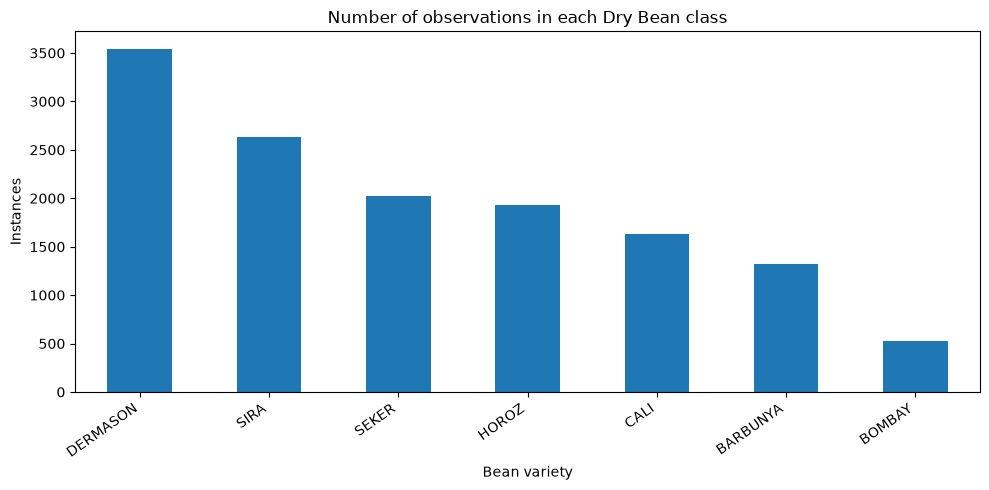

In [4]:
display(X.describe().T)
plt.figure(figsize=(10, 5))
y.value_counts().plot(kind="bar")
plt.title("Number of observations in each Dry Bean class")
plt.xlabel("Bean variety"); plt.ylabel("Instances")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 4. Prepare training and test data
Use a stratified 80:20 split. All five models use this same split. Scaling is applied within pipelines for Logistic Regression, KNN, Gaussian Naive Bayes and SVM; Decision Tree is not scaled.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
display(y_train.value_counts(normalize=True).sort_index().rename("Training proportion").to_frame())

Training rows: 10888
Test rows: 2723


,Training proportion
Class,
BARBUNYA,0.097079
BOMBAY,0.038391
CALI,0.119765
DERMASON,0.260562
HOROZ,0.141624
SEKER,0.148880
SIRA,0.193699


## 5. Define the five classification models

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=2),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ])
}
for name in models:
    print("-", name)

- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine


## 6. Train models and calculate evaluation metrics
AUC is macro-averaged one-vs-rest (OVR) for this multi-class dataset. Precision, Recall and F1 use macro averaging so each class is weighted equally. MCC uses scikit-learn's multi-class implementation.

In [7]:
results, trained_models, prediction_store = [], {}, {}
for model_name, model in models.items():
    print("Training", model_name)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)
    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_probability, multi_class="ovr",
                             average="macro", labels=model.classes_),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })
    trained_models[model_name] = model
    prediction_store[model_name] = y_pred

metrics_df = pd.DataFrame(results).set_index("ML Model Name")
display(metrics_df.round(4))

Training Logistic Regression
Training Decision Tree
Training K-Nearest Neighbors
Training Gaussian Naive Bayes
Training Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
Decision Tree,0.8884,0.9531,0.9038,0.9041,0.9036,0.8652
K-Nearest Neighbors,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


## 7. Compare model performance

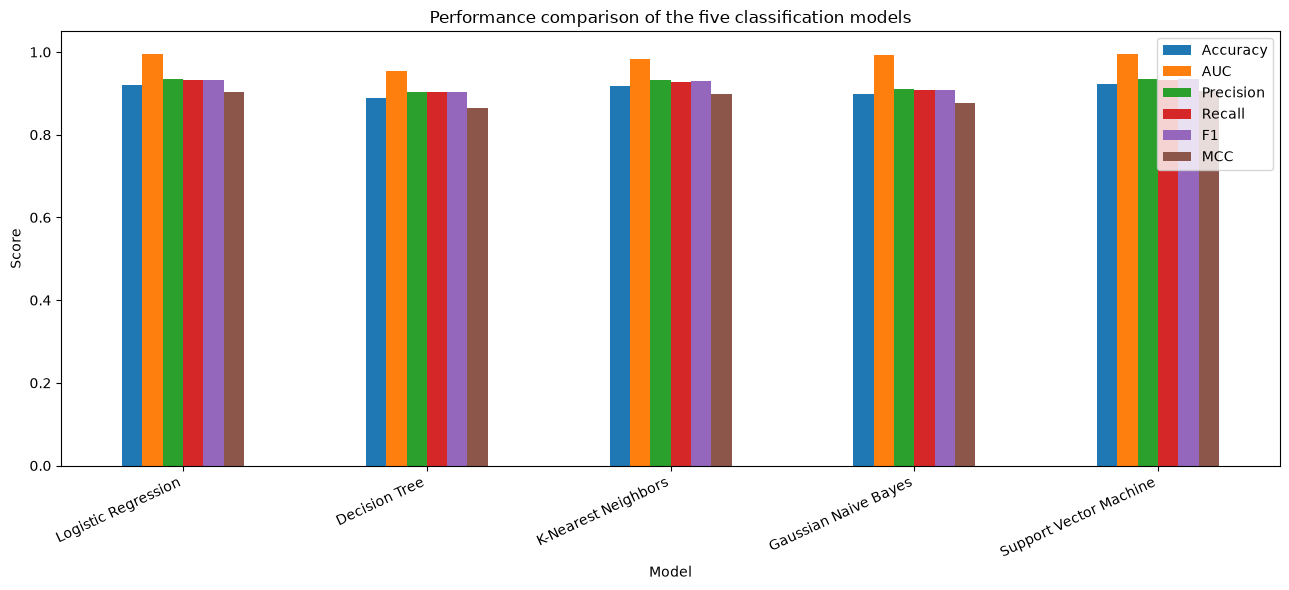

Metrics saved to: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\outputs\metrics_summary.csv


In [8]:
metrics_path = OUTPUT_DIR / "metrics_summary.csv"
metrics_df.to_csv(metrics_path, float_format="%.6f")
ax = metrics_df.plot(kind="bar", figsize=(13, 6), ylim=(0, 1.05))
ax.set_title("Performance comparison of the five classification models")
ax.set_ylabel("Score"); ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
print("Metrics saved to:", metrics_path.resolve())

## 8. Confusion matrices and classification reports

\n======================================================================
Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.85      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



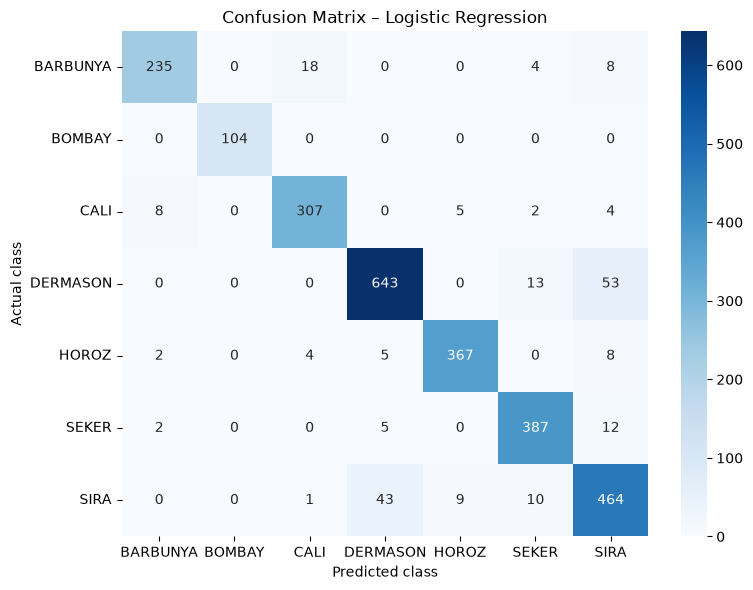

\n======================================================================
Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.85      0.91      0.88       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.92      0.89      0.90       326
    DERMASON       0.87      0.90      0.88       709
       HOROZ       0.94      0.93      0.94       386
       SEKER       0.92      0.93      0.92       406
        SIRA       0.84      0.78      0.81       527

    accuracy                           0.89      2723
   macro avg       0.90      0.90      0.90      2723
weighted avg       0.89      0.89      0.89      2723



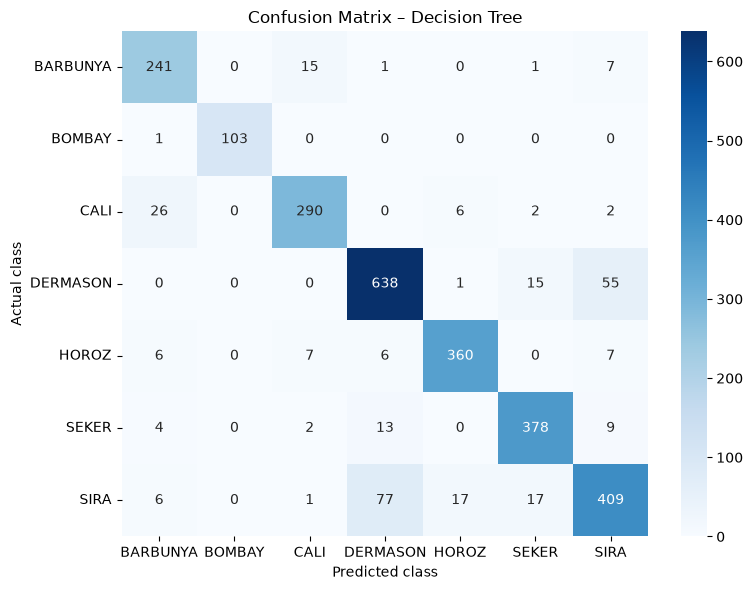

\n======================================================================
K-Nearest Neighbors
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



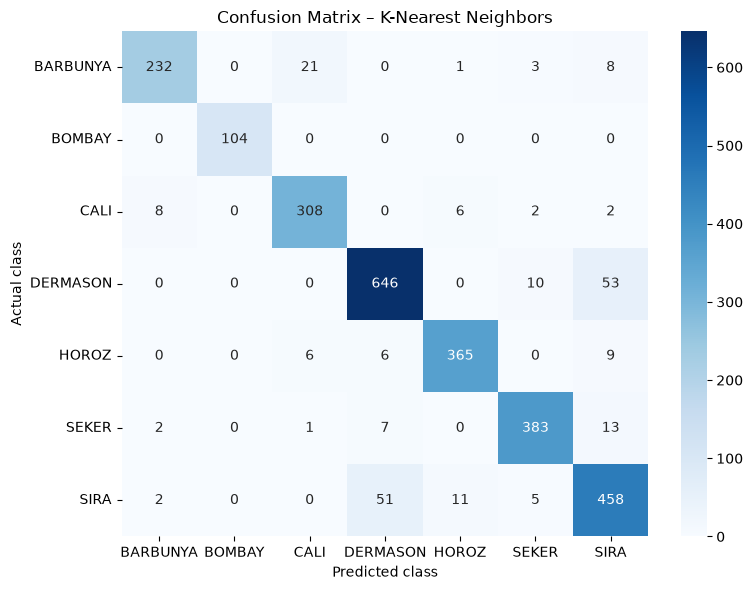

\n======================================================================
Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.80      0.85       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.93      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.89      0.84       527

    accuracy                           0.90      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.90      0.90      0.90      2723



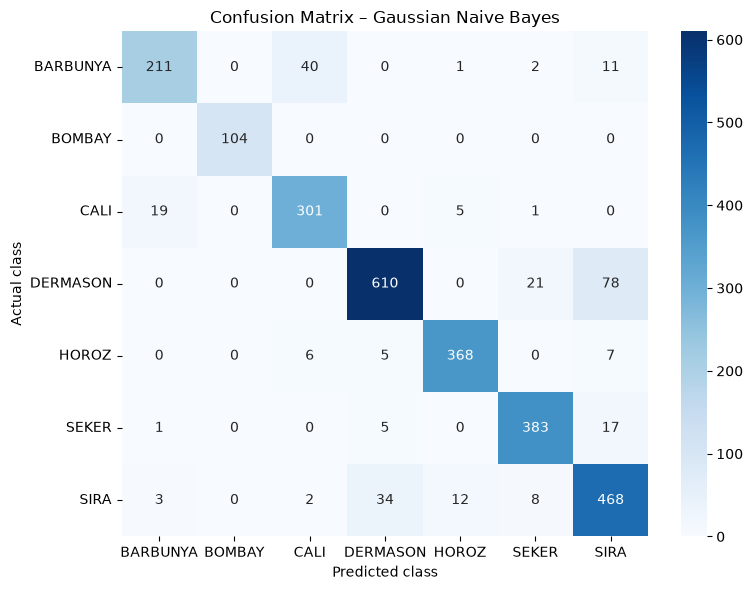

\n======================================================================
Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



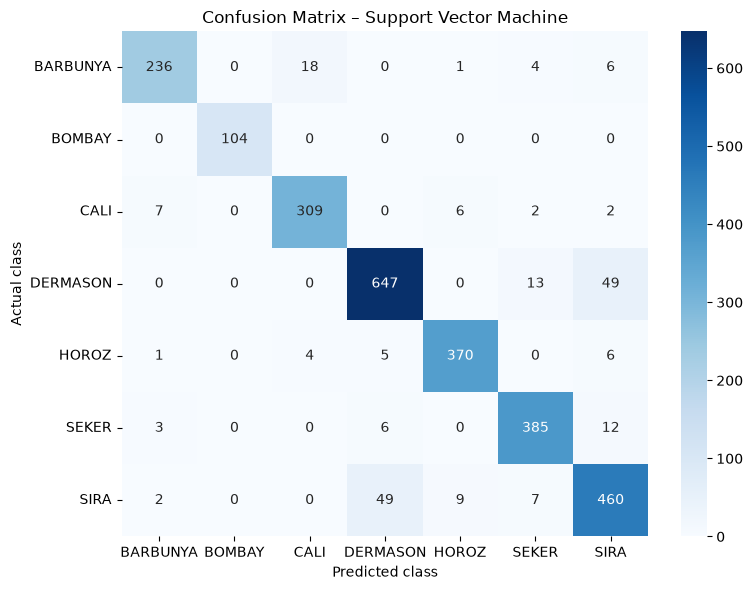

In [9]:
class_labels = sorted(y.unique())
for model_name, y_pred in prediction_store.items():
    print("\\n" + "=" * 70)
    print(model_name)
    print(classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title("Confusion Matrix – " + model_name)
    plt.xlabel("Predicted class"); plt.ylabel("Actual class")
    plt.tight_layout(); plt.show()

## 9. Identify the best-performing model
The ranking rule below compares macro F1 first, then AUC, then MCC. Review the complete metric table and confusion matrices before writing your final interpretation.

In [10]:
ranking = metrics_df.sort_values(["F1", "AUC", "MCC"], ascending=False)
display(ranking.round(4))
winner = ranking.index[0]
print("Top model under the stated ranking rule:", winner)
display(metrics_df.loc[[winner]].round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059
Logistic Regression,0.9207,0.9948,0.9349,0.9314,0.9329,0.9042
K-Nearest Neighbors,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773
Decision Tree,0.8884,0.9531,0.9038,0.9041,0.9036,0.8652


Top model under the stated ranking rule: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Support Vector Machine,0.9221,0.9949,0.9359,0.933,0.9343,0.9059


## 10. Save trained models and test data
The Streamlit application will load these saved pipelines and evaluate the uploaded CSV. It must not retrain on uploaded test data. The test CSV contains all input features and the target column.

In [11]:
model_file_map = {}
for model_name, fitted_model in trained_models.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    model_path = MODEL_DIR / f"{safe_name}.joblib"
    joblib.dump(fitted_model, model_path)
    model_file_map[model_name] = model_path.name

test_data = X_test.copy()
test_data["Class"] = y_test.values
test_data_path = DATA_DIR / "test_data.csv"
test_data.to_csv(test_data_path, index=False)

metadata = {
    "target_column": "Class",
    "feature_columns": list(X.columns),
    "class_labels": [str(v) for v in sorted(y.unique())],
    "model_files": model_file_map,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "auc_method": "macro one-vs-rest"
}
metadata_path = OUTPUT_DIR / "model_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved models:")
for name, filename in model_file_map.items():
    print(name, "->", MODEL_DIR / filename)
print("Test data:", test_data_path.resolve())
print("Metadata:", metadata_path.resolve())
print("Test CSV shape:", test_data.shape)

Saved models:
Logistic Regression -> C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\logistic_regression.joblib
Decision Tree -> C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\decision_tree.joblib
K-Nearest Neighbors -> C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\k_nearest_neighbors.joblib
Gaussian Naive Bayes -> C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\gaussian_naive_bayes.joblib
Support Vector Machine -> C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\support_vector_machine.joblib
Test data: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\data\test_data.csv
Metadata: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\outputs\model_metadata.json
Test CSV shape: (2723, 17)


## 11. Final verification

In [12]:
required_files = [MODEL_DIR / name for name in model_file_map.values()]
required_files += [test_data_path, metrics_path, metadata_path]
for path in required_files:
    print(("OK" if path.exists() else "MISSING") + ":", path)
assert all(path.exists() for path in required_files)
assert test_data.columns[-1] == "Class"
assert list(test_data.columns[:-1]) == list(X.columns)
print("\\nNotebook workflow completed. Use the displayed results to write model-specific observations.")

OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\logistic_regression.joblib
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\decision_tree.joblib
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\k_nearest_neighbors.joblib
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\gaussian_naive_bayes.joblib
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\models\support_vector_machine.joblib
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\data\test_data.csv
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\outputs\metrics_summary.csv
OK: C:\Users\Siddarth\OneDrive\Documents\BITS_ML_Assignment_2\outputs\model_metadata.json
\nNotebook workflow completed. Use the displayed results to write model-specific observations.
